## Grupo 17:
Alicia Mei García Morín (100498828)
Ana Grima Vázquez de Prada (100495785)

El objetivo de esta práctica es construir un modelo de aprendizaje automático capaz de predecir si un cliente bancario suscribirá un depósito a plazo.
En este notebook se construye el modelo: contiene el EDA, la métrica de evaluación, los métodos básicos y avanzados, la evaluación y modelo final.

# 2. EDA Simplificado

En esta sección se realiza un análisis exploratorio básico del dataset con el objetivo de entender su estructura y preparar el posterior preprocesamiento.

## 2.1 Dimensiones del dataset

In [ ]:
df.shape

(11000, 17)

El dataset contiene:
- 11000 instancias (filas) = número de clientes
- 17 atributos (columnas) = número de variables



In [ ]:
import pandas as pd

df = pd.read_pickle("bank_13.pkl")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


## 2.2 Tipos de variables y de problema

In [ ]:
df.dtypes

,0
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64


In [ ]:
categorical_columns = df.select_dtypes(include=["object"]).columns
numerical_columns   = df.select_dtypes(include=["int64","float64"]).columns

print("Categóricas:", list(categorical_columns))
print("Numéricas:", list(numerical_columns))

Categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']
Numéricas: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


Se identifican 10 variables categóricas (de tipo objeto):
- job
- marital
- education
- default
- housing
- loan
- contact
- month
- poutcome
- deposit

Y 7 variables numéricas (aquellas de tipo entero o flotante):
- age
- balance
- day
- duration
- campaign
- pdays
- previous

La variable objetivo es `deposit` y es categórica, por lo que se trata de un problema de clasificación binaria.

## 2.3 Cardinalidad de variables categóricas

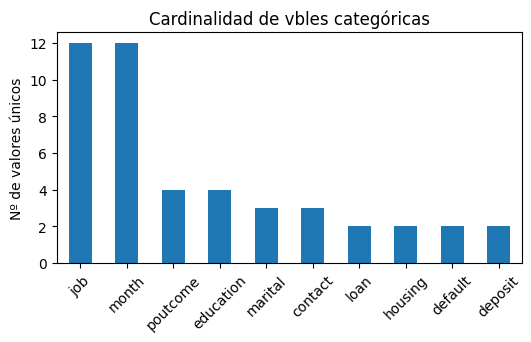

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,3))
cardinality.plot(kind="bar")
plt.title("Cardinalidad de vbles categóricas")
plt.ylabel("Nº de valores únicos")
plt.xticks(rotation=45)
plt.show()

Observamos que hay dos variables con alta cardinalidad (más de 10 valores únicos): `job` y `month` con 12 categorías.

Estas variables se tratarán en el preprocesamiento usando variables dummy.

## 2.4 Valores ausentes

In [ ]:
print("How many missing values per attribute:")
print("======================================")
print(df.isnull().sum())

How many missing values per attribute:
age            0
job            0
marital      406
education      0
default        0
balance        0
housing        0
loan           0
contact        0
day            0
month          0
duration       0
campaign       0
pdays          0
previous       0
poutcome       0
deposit        0
dtype: int64


In [ ]:
missing_values = df.isnull().sum()
print("\nVariables con missing values:")
print(missing_values[missing_values > 0])


Variables con missing values:
marital    406
dtype: int64


Solo tiene valores ausentes la variable `marital`, con un total de 406, que se tratarán en el preprocesamiento usando la técnica de X

## 2.5 Columnas constantes o tipo ID

In [ ]:
constant_cols = [col for col in df.columns if df[col].nunique() == 1]
print("Columnas constantes:", constant_cols)

id_cols = [col for col in df.columns if df[col].nunique() == len(df)]
print("Columnas tipo ID:", id_cols)

Columnas constantes: []
Columnas tipo ID: []


No se observan columnas constantes o columnas de ID

# 2.6 Desbalanceo

In [ ]:
print("Distribución absoluta de la variable objetivo:")
print("===============================================")
print(df["deposit"].value_counts())

print("\nDistribución porcentual:")
print("========================")
print(df["deposit"].value_counts(normalize=True))

Distribución absoluta de la variable objetivo:
deposit
no     5780
yes    5220
Name: count, dtype: int64

Distribución porcentual:
deposit
no     0.525455
yes    0.474545
Name: proportion, dtype: float64


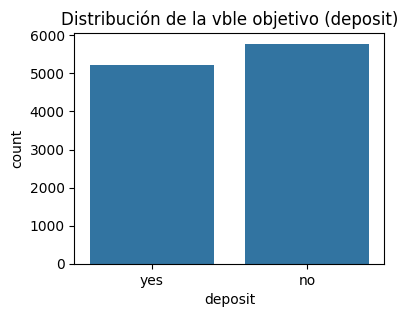

In [ ]:
plt.figure(figsize=(4,3))
sns.countplot(x="deposit", data=df)
plt.title("Distribución de la vble objetivo (deposit)")
plt.show()

La variable `deposit` indica si el cliente suscribió un depósito. Como hemos visto en puntos anteriores, se trata de un problema de clasificación binaria.
La distribución de clases es:

- 52.55% para la clase "no"
- 47.45% para la clase "yes"

Por tanto, el dataset no tiene un desbalanceo significativo. Como se observa en la gráfica, la variable objetivo presenta una distribución relativamente equilibrada entre ambas clases.

## 2.7 Análisis de las variables numéricas


In [ ]:
df[numerical_columns].describe()

,age,balance,day,duration,campaign,pdays,previous
count,11000.000000,11000.000000,11000.000000,11000.000000,11000.00000,11000.000000,11000.000000
mean,41.252727,1529.139273,15.660818,372.524909,2.50800,51.308636,0.828000
std,11.940474,3217.396248,8.417970,347.515713,2.72221,108.782842,2.282936
min,18.000000,-6847.000000,1.000000,2.000000,1.00000,-1.000000,0.000000
25%,32.000000,122.750000,8.000000,138.000000,1.00000,-1.000000,0.000000
50%,39.000000,549.500000,15.000000,255.000000,2.00000,-1.000000,0.000000
75%,49.000000,1711.000000,22.000000,498.000000,3.00000,20.250000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.00000,854.000000,58.000000


Observamos de nuevo que no existen valores ausentes en las variables numéricas, ya que todas las tienen 11.000 valores.

La variable `age` presenta valores entre 18 y 95 años, lo cual es lo normal.

La variable `balance` tiene valores que van desde -6847 hasta 81204. Esto indicaría que hay clientes con deudas y otros con balances muy altos.

La variable `duration` también presenta una gran dispersión (std ≈ 347) y un máximo bastante elevado (3881 segundos), seguramente algunas llamadas fueron muy largas.

En el caso de `campaign`, aunque la media es baja (≈2.5 contactos), el valor máximo alcanza 63, lo que indica que algunos clientes fueron contactados muchas veces.

La variable `pdays` requiere que la analicemos en profundiad, ya que observamos valores mínimos de -1.

Por último, la variable `previous` muestra que la mayoría de los clientes no habían sido contactados anteriormente (mediana = 0), aunque existen algunos casos con valores elevados (hasta 58 contactos previos).

In [ ]:
print("\nValores más frecuentes de pdays:")
print("===============================")
print(df["pdays"].value_counts().head(15))

print("\nPorcentaje de -1 en pdays:", round(100*n_minus1/len(df), 2), "%")


Valores más frecuentes de pdays:
pdays
-1      8203
 92      105
 182      88
 91       82
 181      79
 183      73
 184      51
 94       42
 93       40
 95       37
 87       34
 90       32
 98       31
 185      30
 187      28
Name: count, dtype: int64

Porcentaje de -1 en pdays: 74.57 %


La variable `pdays` representa el número de días transcurridos desde el último contacto en una campaña anterior.

Observamos que el valor -1 aparece 8203 veces, lo que es el 74.57% del dataset. El -1 no representa un número real de días, sino ausencia de contacto previo. Lo que indica que una gran parte de los clientes no fueron contactados previamente.

Por tanto, el valor -1 no debe interpretarse como un valor numérico válido, lo trataremos en el preprocesamiento.


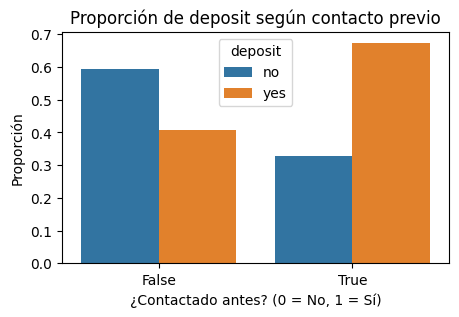

In [ ]:
prop = (
    df_tmp.groupby("contacted_before")["deposit"]
    .value_counts(normalize=True)
    .rename("proportion")
    .reset_index()
)

plt.figure(figsize=(5,3))
sns.barplot(x="contacted_before", y="proportion", hue="deposit", data=prop)

plt.title("Proporción de deposit según contacto previo")
plt.xlabel("¿Contactado antes? (0 = No, 1 = Sí)")
plt.ylabel("Proporción")
plt.show()

Hemos analizado si `pdays` realemente influye en la probabilidad de contratar el depósito. Observamos que la proporción de clientes que contratan el depósito es diferente entre ambos grupos, lo que indica que la variable `pdays` (o el hecho de haber sido contactado antes) contiene información relevante para el modelo.

Según los fundamentos de preprocesamiento vistos en clase, ante valores que no representan información numérica real, pueden aplicarse distintas estrategias como:
- Tratarlos como valores ausentes e imputarlos.
- Transformar el atributo generando nuevas variables que capturen mejor la información relevante.
- Discretizar el atributo en rangos.
- Eliminar la variable si no aporta información significativa.

Como el 74.57% de los valores son -1, hemos pensado que la mejor opción será crear una nueva variable binaria *contacted_before*, que indique si el cliente fue contactado previamente o no. Además de reemplazar el valor -1 por NaN, para que pueda ser tratado adecuadamente en el pipeline de preprocesamiento.

In [ ]:
# Creamos variable binaria que indica si el cliente fue contactado previamente
df["contacted_before"] = (df["pdays"] != -1).astype(int)

# Convertimos -1 en missing
df["pdays"] = df["pdays"].replace(-1, pd.NA)

print(df["pdays"].isnull().sum())
print(df["contacted_before"].value_counts())

8203
contacted_before
0    8203
1    2797
Name: count, dtype: int64


## 2.8 Conclusiones del EDA  

El dataset contiene 11.000 instancias y 17 atributos. Encontramos variables numéricas (`age, balance, day, duration, campaign, pdays, previously`) y categóricas (`job, marital, education, default, housing, loan, contact, month, poutcome`), donde `deposit` es nuestra variable objetivo.

No existen columnas constantes o de ID.

Únicamente tiene valores faltantes  la variable `marital` (406 valores), que deberán imputarse durante el preprocesamiento.

Existen variables categóricas con alta cardinalidad (`job` y `month`), que necesitarán codificación mediante variables dummy.

El problema es de clasificación binaria y el conjunto presenta un desbalanceo leve entre clases (52.55% frente a 47.45%).

Por último, la variable `pdays` presenta el valor -1 en el 74.57% de los casos, indicando ausencia de contacto previo. Dado que este valor no representa un número real de días, se ha decidido crear la variable binaria *contacted_before *y tratar los valores -1 como ausentes, permitiendo así un tratamiento más adecuado en el pipeline de preprocesamiento.



# 3. Decisiones de evaluación

En esta sección se define la estrategia de evaluación del modelo, incluyendo la partición de los datos, la métrica seleccionada y el procedimiento de validación que se utilizará para estimar el rendimiento del modelo.

## 3.1 Evaluación outer

La estimación del rendimiento futuro se realizará mediante Holdout, dividiendo el conjunto de datos en train (2/3) y test (1/3).
Al tratarse de un problema de clasificación binaria con datos bastante balanceados (52.55% frente a 47.45%), decidimos usar la métrica Accuracy como medida principal de evaluación, que calcula la proporción total de aciertos.
El conjunto de test se usa únicamente al final de la práctica para estimar el rendimiento futuro del modelo seleccionado, evitando así problemas de data leakage.

In [ ]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=["deposit"])
y = df["deposit"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=1/3,
    stratify=y,
    random_state=42
)
print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

## 3.2 Evaluación inner

Para comparar modelos y optimizar los hiperparámetros, decidimos usar la validación cruzada estratificada de 5 particiones (Stratified 5-fold Cross Validation), ya que consideramos que es más óptima para un equilibrio entre coste y estabilidad de la estimación. En esta, el conjunto de entrenamiento se divide en 5 subconjuntos y en cada iteración, el modelo se entrena utilizando 4 de los subconjuntos (80% del train), evaluándose en el subconjunto restante (20%).

Este proceso se repite 5 veces, de modo que cada subconjunto actúa una vez como conjunto de validación.

Respecto al número de particiones, consideramos otras alternativas:
•	10-fold cross validation sería más estable, pero duplica el coste computacional; Leave-One-Out Cross Validation (LOOCV) sería demasiado costoso en esta práctica (11.000 entrenamientos por modelo); Repeated Holdout también podría utilizarse, pero puede producir solapamientos entre particiones y resultados menos consistentes.

Se ha optado por validación cruzada frente a un simple holdout interno porque nos ha parecido más estable, ya que este último depende demasiado de una única partición de los datos.

In [ ]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)